# Desarrollo técnico · Hotel Valle de Cocora
**Programación Aplicada · Universidad de La Sabana · proyecto tercer corte**

Este notebook convierte la evidencia del EDA en **modelos y reglas de decisión** para las tres preguntas de enfoque:

| # | Pregunta | Entregable técnico |
|---|---|---|
| P1 | ¿Se puede anticipar cuántas reservas se cancelarán para aceptar reservas adicionales? | Regla de reservas adicionales = percentil 10 de las cancelaciones esperadas, evaluada noche a noche |
| P2 | ¿Qué clientes cancelan más y cuánto se ahorra pidiendo pago por adelantado solo a ellos? | Umbral de alto riesgo y ahorro neto, con sensibilidad a la pérdida de reservas |
| P3 | En Booking y Airbnb, ¿cuánto baja la cancelación si las Flexibles pasan a Moderada o pagan depósito? | Escenarios por canal y tope de pérdida de volumen para el piloto |

**Reglas del juego (heredadas del EDA):** unidad de P1 = noche de llegada; entrenamiento antes del 1-jul-2024 y prueba del 1-jul-2024 al 18-jun-2025 (353 noches); `ingreso_total` queda fuera de los predictores (fuga de información); las cifras en pesos son de la base, que equivale a ≈ 8 veces la capacidad de 38 habitaciones, por lo que se leen como proporciones.

## 0. Configuración y preparación de datos

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score, brier_score_loss

sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS, VERDE, NARANJA = "#2563eb", "#dc2626", "#9ca3af", "#16a34a", "#f59e0b"
SEMILLA = 42
INI_VENTANA, FIN_VENTANA = pd.Timestamp("2023-05-01"), pd.Timestamp("2025-06-18")
CORTE_TEST = pd.Timestamp("2024-07-01")
rng = np.random.default_rng(SEMILLA)
CIF = {}                                           # aquí se guardan las cifras que alimentan el resto de entregables
pct = lambda ax, e="y": (ax.yaxis if e == "y" else ax.xaxis).set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
M = lambda x: f"${x/1e6:,.0f} M"

# Misma limpieza que el EDA: sin duplicados, faltantes como categoría propia, ventana confiable
raw = pd.read_csv("../../datos/hotel_reservas.csv", parse_dates=["fecha_reserva", "fecha_llegada"])
df = raw.drop_duplicates().copy()
df[["canal", "pais_origen"]] = df[["canal", "pais_origen"]].fillna("No registrado")
df["ingreso_potencial"] = df.tarifa_noche * df.noches
df["ingreso_perdido"] = df.ingreso_potencial * df.cancelada
dv = df[df.fecha_llegada.between(INI_VENTANA, FIN_VENTANA)].copy().reset_index(drop=True)
es_tr = dv.fecha_llegada < CORTE_TEST
print(f"Base completa: {len(df):,} | ventana: {len(dv):,} | entrenamiento: {es_tr.sum():,} | prueba: {(~es_tr).sum():,}")

Base completa: 100,000 | ventana: 86,168 | entrenamiento: 47,018 | prueba: 39,150


## 1. Modelo de cancelación (base de P1, P2 y P3)

**Qué se hace:** un gradient boosting que estima, para cada reserva, la probabilidad de que se cancele usando solo información disponible al reservar. **Por qué este modelo:** en el EDA tuvo un AUC equivalente a la regresión logística (0,77), lo que indica que la señal es robusta; se conserva el boosting porque captura interacciones (anticipación × política × depósito) sin ajustar a mano.

Dos verificaciones que importan más que el AUC: (1) que las **probabilidades estén calibradas** (si dice 30 %, que cancele ≈ 30 %), porque P1 las suma y P2 las compara con un umbral; (2) que el modelo **no dependa del periodo atípico de 2023**.

AUC en prueba: 0.770 | Brier: 0.1312 (referencia con tasa fija: 0.1536)
Cancelaciones reales en prueba: 7,420 | esperadas por el modelo: 7,455


AUC entrenando solo con 2024: 0.768 (vs 0.770 con todo el entrenamiento)


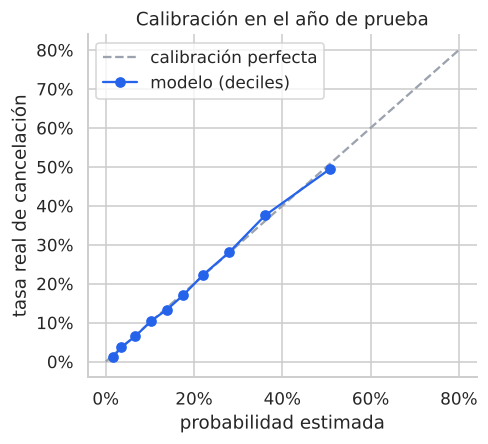

Máxima desviación entre probabilidad estimada y tasa real en un decil: 1.4 pp


In [2]:
feats_cat = ["tipo_habitacion", "canal", "pais_origen", "politica_cancelacion"]
feats_num = ["anticipacion_dias", "noches", "adultos", "ninos", "tarifa_noche", "deposito_pagado", "huesped_recurrente",
             "solicitudes_especiales", "cancelaciones_previas", "incluye_desayuno", "mes_llegada"]
enc = OrdinalEncoder().fit(dv[feats_cat])            # codifica las categorías como enteros (el boosting las trata como categóricas)

def matriz(d):
    X = d[feats_cat + feats_num].copy()
    X[feats_cat] = enc.transform(d[feats_cat]).astype(int)
    return X

def entrenar(mascara):
    m = HistGradientBoostingClassifier(max_iter=200, learning_rate=.08, random_state=SEMILLA,
                                       categorical_features=[list(feats_cat + feats_num).index(c) for c in feats_cat])
    return m.fit(matriz(dv[mascara]), dv.cancelada[mascara])

modelo = entrenar(es_tr)
dv["p"] = modelo.predict_proba(matriz(dv))[:, 1]     # probabilidad estimada (en la prueba es una predicción "fuera de muestra")
te = dv[~es_tr].copy()                               # año de prueba

auc = roc_auc_score(te.cancelada, te.p); brier = brier_score_loss(te.cancelada, te.p)
base_brier = brier_score_loss(te.cancelada, np.full(len(te), dv.cancelada[es_tr].mean()))
print(f"AUC en prueba: {auc:.3f} | Brier: {brier:.4f} (referencia con tasa fija: {base_brier:.4f})")
print(f"Cancelaciones reales en prueba: {te.cancelada.sum():,} | esperadas por el modelo: {te.p.sum():,.0f}")

# Robustez: ¿cambia algo si se entrena sin 2023 (periodo atípico)? Se entrena desde ene-2024 y se evalúa igual.
m24 = entrenar(es_tr & (dv.fecha_llegada >= "2024-01-01"))
auc24 = roc_auc_score(te.cancelada, m24.predict_proba(matriz(te))[:, 1])
print(f"AUC entrenando solo con 2024: {auc24:.3f} (vs {auc:.3f} con todo el entrenamiento)")
CIF.update(auc=auc, auc_sin2023=auc24, brier=brier, brier_base=base_brier, canc_real_test=int(te.cancelada.sum()), canc_esp_test=float(te.p.sum()))

# Calibración por deciles de probabilidad
te["decil"] = pd.qcut(te.p, 10, labels=False, duplicates="drop")
cal = te.groupby("decil").agg(p_media=("p", "mean"), tasa_real=("cancelada", "mean"), n=("p", "size"))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, .8], [0, .8], "--", color=GRIS, label="calibración perfecta"); ax.plot(cal.p_media, cal.tasa_real, "o-", color=AZUL, label="modelo (deciles)")
ax.set_xlabel("probabilidad estimada"); ax.set_ylabel("tasa real de cancelación"); pct(ax); pct(ax, "x"); ax.legend(); ax.set_title("Calibración en el año de prueba")
plt.tight_layout(); plt.show()
CIF["calib_max_desv_pp"] = float((cal.p_media - cal.tasa_real).abs().max() * 100)
print(f"Máxima desviación entre probabilidad estimada y tasa real en un decil: {CIF['calib_max_desv_pp']:.1f} pp")

## 2. Pregunta 1 · Reservas adicionales

**Idea:** cada noche hay un número incierto de cancelaciones. Con la probabilidad de cada reserva programada para esa noche se simula la distribución de cancelaciones y se acepta como reservas adicionales el **percentil 10**: con 90 % de probabilidad se cancelarán al menos tantas, de modo que las reservas adicionales casi siempre encuentran habitación.

**Cómo se mide (definiciones del PDF):**
- *Cobertura* = cancelaciones cubiertas por reservas adicionales ÷ cancelaciones totales.
- *Incidencia* = noches en que se aceptaron más reservas adicionales que cancelaciones reales (algún huésped se queda sin cuarto).
- *MAE* = error absoluto medio entre cancelaciones esperadas y reales por noche.

Se compara con una **regla ingenua** (la misma tasa histórica para todas las reservas) para ver qué aporta el modelo.

In [3]:
NSIM = 4000
def colchon(ps, q=0.10):
    """Percentil q de las cancelaciones de una noche, simulando cada reserva como Bernoulli(p)."""
    sims = (rng.random((NSIM, len(ps))) < ps).sum(axis=1)
    return int(np.quantile(sims, q, method="lower")), sims

tasa_hist = dv.cancelada[es_tr].mean()                 # regla ingenua: misma tasa para todos
noches = te.groupby(te.fecha_llegada.dt.normalize())
filas = []
for fecha, g in noches:
    reales = int(g.cancelada.sum())
    ps_m, ps_n = g.p.values, np.full(len(g), tasa_hist)
    filas.append(dict(fecha=fecha, reservas=len(g), reales=reales, esp_modelo=ps_m.sum(), esp_ingenua=ps_n.sum(),
                      extra_modelo=colchon(ps_m)[0], extra_ingenua=colchon(ps_n)[0]))
n1 = pd.DataFrame(filas).set_index("fecha")
print(f"Noches de prueba: {len(n1)}")

def kpis_p1(extra, reales):
    return dict(cobertura=np.minimum(extra, reales).sum() / reales.sum(), incidencia=(extra > reales).mean())
res = pd.DataFrame({"Modelo": kpis_p1(n1.extra_modelo, n1.reales), "Regla ingenua": kpis_p1(n1.extra_ingenua, n1.reales)}).T
res["MAE"] = [np.abs(n1.esp_modelo - n1.reales).mean(), np.abs(n1.esp_ingenua - n1.reales).mean()]
res["Reservas adicionales / noche"] = [n1.extra_modelo.mean(), n1.extra_ingenua.mean()]
display(res.style.format({"cobertura": "{:.1%}", "incidencia": "{:.1%}", "MAE": "{:.2f}", "Reservas adicionales / noche": "{:.1f}"}))
CIF.update(p1_cobertura=res.loc["Modelo", "cobertura"], p1_incidencia=res.loc["Modelo", "incidencia"], p1_mae=res.loc["Modelo", "MAE"],
           p1_extra_media=float(n1.extra_modelo.mean()), p1_cobertura_ing=res.loc["Regla ingenua", "cobertura"],
           p1_incidencia_ing=res.loc["Regla ingenua", "incidencia"], p1_mae_ing=res.loc["Regla ingenua", "MAE"], n_noches=len(n1))

Noches de prueba: 353


,cobertura,incidencia,MAE,Reservas adicionales / noche
Modelo,76.8%,7.6%,3.07,16.3
Regla ingenua,75.1%,9.1%,3.24,16.0


,q,cobertura,incidencia,extra_media
0,P2%,64.6%,1.4%,13.6
1,P5%,71.1%,3.4%,15.0
2,P10%,76.7%,7.6%,16.3
3,P15%,80.6%,11.3%,17.2
4,P20%,83.2%,16.1%,17.9
5,P30%,87.3%,28.0%,19.0
6,P50%,92.7%,47.9%,21.0


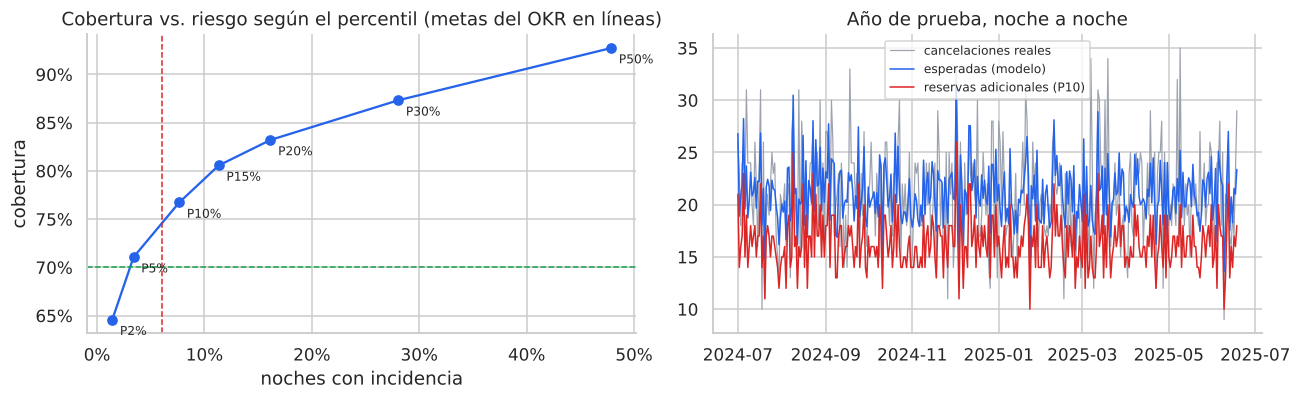

In [4]:
# Sensibilidad: ¿cuánta cobertura se gana (y cuánto riesgo se asume) al cambiar el percentil?
qs = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50]
curva = []
for q in qs:
    ex = np.array([colchon(g.p.values, q)[0] for _, g in noches]); re_ = n1.reales.values
    curva.append(dict(q=q, cobertura=np.minimum(ex, re_).sum() / re_.sum(), incidencia=(ex > re_).mean(), extra_media=ex.mean()))
curva = pd.DataFrame(curva)
display(curva.style.format({"q": "P{:.0%}", "cobertura": "{:.1%}", "incidencia": "{:.1%}", "extra_media": "{:.1f}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(curva.incidencia, curva.cobertura, "o-", color=AZUL)
for _, r in curva.iterrows(): ax[0].annotate(f"P{r.q:.0%}", (r.incidencia, r.cobertura), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax[0].axhline(.70, color=VERDE, ls="--", lw=1); ax[0].axvline(.06, color=ROJO, ls="--", lw=1)
ax[0].set_xlabel("noches con incidencia"); ax[0].set_ylabel("cobertura"); pct(ax[0]); pct(ax[0], "x"); ax[0].set_title("Cobertura vs. riesgo según el percentil (metas del OKR en líneas)")
ax[1].plot(n1.index, n1.reales, color=GRIS, lw=.8, label="cancelaciones reales"); ax[1].plot(n1.index, n1.esp_modelo, color=AZUL, lw=1, label="esperadas (modelo)")
ax[1].plot(n1.index, n1.extra_modelo, color=ROJO, lw=1, label="reservas adicionales (P10)")
ax[1].legend(fontsize=8); ax[1].set_title("Año de prueba, noche a noche")
plt.tight_layout(); plt.show()
CIF["p1_curva"] = curva.round(4).to_dict("records")

## 3. Pregunta 2 · Pago por adelantado focalizado

**Idea:** pedir depósito a todos espanta demanda; pedirlo solo a quienes tienen alta probabilidad de cancelar protege ingreso con poco costo. Hay que decidir (a) **a quién** (umbral de probabilidad) y (b) **cuánto vale**.

**Cómo se estima el ahorro, sin inflarlo:**
1. *Efecto del depósito:* se mide **dentro de las políticas Flexible y Moderada** (donde el depósito es una decisión) y **solo con datos de entrenamiento**: la cancelación con depósito es una fracción *r* de la de sin depósito. Es una asociación, no causalidad, así que también se prueban versiones más conservadoras (mitad y cuarto del efecto).
2. *Ingreso protegido* = ingreso perdido por las reservas marcadas × (1 − *r*).
3. *Costo:* una fracción *g* de las reservas marcadas desiste al exigirles pago, y se pierde el ingreso de las que sí se habrían quedado.

In [5]:
fm_tr = dv[es_tr & dv.politica_cancelacion.isin(["Flexible", "Moderada"])]
t_sin, t_con = fm_tr[fm_tr.deposito_pagado == 0].cancelada.mean(), fm_tr[fm_tr.deposito_pagado == 1].cancelada.mean()
r = t_con / t_sin
print(f"Entrenamiento, Flexible+Moderada: sin depósito {t_sin:.1%} | con depósito {t_con:.1%} → factor r = {r:.2f}")
CIF.update(p2_t_sin=t_sin, p2_t_con=t_con, p2_r=r)

sin = te[te.deposito_pagado == 0]                       # reservas del año de prueba sin pago anticipado
recuperable = sin.ingreso_perdido.sum() * (1 - r)       # si se exigiera depósito a TODAS
filas = []
for t in [.10, .15, .20, .25, .30, .35, .40, .50, .60]:
    f = sin[sin.p > t]
    prot = f.ingreso_perdido.sum() * (1 - r)
    quedan = (f.ingreso_potencial * (1 - f.cancelada)).sum()      # ingreso de las marcadas que sí se habrían quedado
    filas.append(dict(umbral=t, marcadas=len(f), pct_marcadas=len(f) / len(sin), tasa_real=f.cancelada.mean(),
                      protegido=prot, pct_recuperable=prot / recuperable, costo_g5=.05 * quedan, costo_g10=.10 * quedan,
                      neto_g5=prot - .05 * quedan, neto_g10=prot - .10 * quedan))
u = pd.DataFrame(filas)
disp = u.assign(protegido=u.protegido.map(M), costo_g5=u.costo_g5.map(M), costo_g10=u.costo_g10.map(M), neto_g5=u.neto_g5.map(M), neto_g10=u.neto_g10.map(M))
display(disp.style.format({"umbral": "{:.0%}", "marcadas": "{:,.0f}", "pct_marcadas": "{:.0%}", "tasa_real": "{:.1%}", "pct_recuperable": "{:.0%}"}))
print(f"Si se exigiera depósito a todas las reservas sin pago: ingreso protegido ≈ {M(recuperable)} (techo, sin costo de demanda)")

Entrenamiento, Flexible+Moderada: sin depósito 27.7% | con depósito 14.7% → factor r = 0.53


,umbral,marcadas,pct_marcadas,tasa_real,protegido,pct_recuperable,costo_g5,costo_g10,neto_g5,neto_g10
0,10%,"18,924",91%,28.9%,"$2,104 M",98%,$553 M,"$1,106 M","$1,551 M",$998 M
1,15%,"15,787",76%,32.3%,"$1,955 M",91%,$440 M,$881 M,"$1,515 M","$1,075 M"
2,20%,"12,773",62%,35.9%,"$1,758 M",82%,$338 M,$676 M,"$1,420 M","$1,082 M"
3,25%,"9,938",48%,39.5%,"$1,520 M",71%,$247 M,$494 M,"$1,273 M","$1,025 M"
4,30%,"7,670",37%,42.8%,"$1,266 M",59%,$180 M,$360 M,"$1,086 M",$906 M
5,35%,"5,682",27%,45.9%,$997 M,46%,$125 M,$250 M,$872 M,$747 M
6,40%,"3,853",19%,49.2%,$730 M,34%,$80 M,$160 M,$649 M,$569 M
7,50%,"1,479",7%,56.2%,$329 M,15%,$27 M,$54 M,$302 M,$275 M
8,60%,469,2%,63.1%,$109 M,5%,$7 M,$14 M,$102 M,$95 M


Si se exigiera depósito a todas las reservas sin pago: ingreso protegido ≈ $2,151 M (techo, sin costo de demanda)


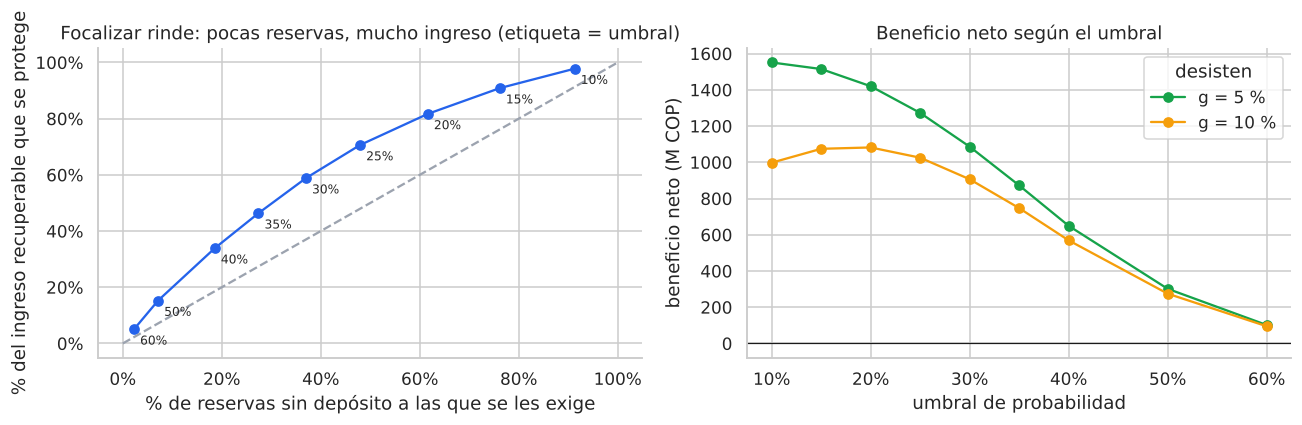

Umbral 30 %: 37% de las reservas sin pago, protege $1,266 M (59% del recuperable); neto $1,086 M (g=5 %) / $906 M (g=10 %)
Umbral con mayor neto (g=5 %): 10% → $1,551 M
  Si el depósito logra 100% del efecto observado: protegido ≈ $1,266 M (umbral 30 %)
  Si el depósito logra 50% del efecto observado: protegido ≈ $633 M (umbral 30 %)
  Si el depósito logra 25% del efecto observado: protegido ≈ $316 M (umbral 30 %)


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ax[0].plot(u.pct_marcadas, u.pct_recuperable, "o-", color=AZUL); ax[0].plot([0, 1], [0, 1], "--", color=GRIS)
for _, x in u.iterrows(): ax[0].annotate(f"{x.umbral:.0%}", (x.pct_marcadas, x.pct_recuperable), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax[0].set_xlabel("% de reservas sin depósito a las que se les exige"); ax[0].set_ylabel("% del ingreso recuperable que se protege")
pct(ax[0]); pct(ax[0], "x"); ax[0].set_title("Focalizar rinde: pocas reservas, mucho ingreso (etiqueta = umbral)")
ax[1].plot(u.umbral, u.neto_g5 / 1e6, "o-", color=VERDE, label="g = 5 %"); ax[1].plot(u.umbral, u.neto_g10 / 1e6, "o-", color=NARANJA, label="g = 10 %")
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xlabel("umbral de probabilidad"); ax[1].set_ylabel("beneficio neto (M COP)"); pct(ax[1], "x"); ax[1].legend(title="desisten"); ax[1].set_title("Beneficio neto según el umbral")
plt.tight_layout(); plt.show()

# Resultado con el umbral del PDF (30 %) y con el que maximiza el neto (g = 5 %)
u30 = u[u.umbral == .30].iloc[0]; ub = u.loc[u.neto_g5.idxmax()]
print(f"Umbral 30 %: {u30.pct_marcadas:.0%} de las reservas sin pago, protege {M(u30.protegido)} ({u30.pct_recuperable:.0%} del recuperable); neto {M(u30.neto_g5)} (g=5 %) / {M(u30.neto_g10)} (g=10 %)")
print(f"Umbral con mayor neto (g=5 %): {ub.umbral:.0%} → {M(ub.neto_g5)}")
# Efecto conservador: si el depósito solo logra la mitad / un cuarto de la reducción observada
for frac in (1, .5, .25):
    prot = (1 - r * frac - (1 - frac)) if False else sin[sin.p > .30].ingreso_perdido.sum() * (1 - r) * frac
    print(f"  Si el depósito logra {frac:.0%} del efecto observado: protegido ≈ {M(prot)} (umbral 30 %)")
CIF.update(p2_pct_marcadas=u30.pct_marcadas, p2_tasa_alto=u30.tasa_real, p2_protegido=u30.protegido, p2_pct_recup=u30.pct_recuperable,
           p2_neto_g5=u30.neto_g5, p2_neto_g10=u30.neto_g10, p2_recuperable=recuperable, p2_umbral_opt=ub.umbral, p2_neto_opt=ub.neto_g5,
           p2_prot_mitad=u30.protegido * .5, p2_prot_cuarto=u30.protegido * .25, p2_n_sin=len(sin))

## 4. Pregunta 3 · Políticas por canal (Booking y Airbnb)

**Idea:** en cada canal, las reservas **Flexibles sin depósito** son las más volátiles. Se simula qué pasaría si pasaran a **Moderada** o si **pagaran depósito**, usando la tasa observada de cada celda (canal × política × depósito) y, como contraste, el modelo con la característica cambiada. Es un **techo optimista**: supone que la demanda no cambia.

**Punto de equilibrio:** si por endurecer la política se pierde más de *g\** = 1 − (1 − *p*ₕₒᵧ) / (1 − *p*ₙᵤₑᵥₐ) de las reservas afectadas, las estancias confirmadas bajan en lugar de subir. Con eso se fija el **tope de caída de volumen** del KR2.

In [7]:
cel = dv.groupby(["canal", "politica_cancelacion", "deposito_pagado"]).cancelada.agg(["mean", "size"])   # tasas por celda (ventana completa)
filas = []
for canal in ["Booking", "Airbnb"]:
    d = dv[dv.canal == canal]; tasa_canal = df[df.canal == canal].cancelada.mean()
    af = te[(te.canal == canal) & (te.politica_cancelacion == "Flexible") & (te.deposito_pagado == 0)]   # reservas afectadas (año de prueba)
    p_act = cel.loc[(canal, "Flexible", 0), "mean"]; ticket = af.ingreso_potencial.mean()
    for nombre, clave in [("Flexible → Moderada", (canal, "Moderada", 0)), ("Flexible + depósito", (canal, "Flexible", 1))]:
        p_new = cel.loc[clave, "mean"]
        # Tasa del canal completo después del cambio: se reemplaza la tasa de las afectadas (todo el historial del canal)
        n_c = len(df[df.canal == canal]); n_af = ((df.canal == canal) & (df.politica_cancelacion == "Flexible") & (df.deposito_pagado == 0)).sum()
        tasa_nueva = tasa_canal - n_af / n_c * (p_act - p_new)
        g_be = 1 - (1 - p_act) / (1 - p_new)
        g_tope = 1 - ((1 - p_act) + .5 * (p_act - p_new)) / (1 - p_new)            # pérdida con la que aún se conserva la mitad del beneficio
        # Contraste con el modelo: se cambia la característica y se recalcula la probabilidad media de las afectadas
        cf = af.copy()
        if "Moderada" in nombre: cf["politica_cancelacion"] = "Moderada"
        else: cf["deposito_pagado"] = 1
        p_mod = modelo.predict_proba(matriz(cf))[:, 1].mean()
        filas.append(dict(canal=canal, escenario=nombre, afectadas=len(af), p_flex_hoy=p_act, p_escenario=p_new, p_modelo_ctrfct=p_mod,
                          tasa_canal_hoy=tasa_canal, tasa_canal_nueva=tasa_nueva, recuperable=len(af) * ticket * (p_act - p_new),
                          g_equilibrio=g_be, g_tope=g_tope))
p3 = pd.DataFrame(filas)
disp = p3.assign(recuperable=p3.recuperable.map(M))
display(disp.style.format({"afectadas": "{:,.0f}", "p_flex_hoy": "{:.1%}", "p_escenario": "{:.1%}", "p_modelo_ctrfct": "{:.1%}", "tasa_canal_hoy": "{:.1%}",
                           "tasa_canal_nueva": "{:.1%}", "g_equilibrio": "{:.1%}", "g_tope": "{:.1%}"}))
for _, x in p3.iterrows():
    k = ("bk" if x.canal == "Booking" else "ab") + ("_mod" if "Moderada" in x.escenario else "_dep")
    CIF.update({f"p3_{k}_hoy": x.tasa_canal_hoy, f"p3_{k}_nueva": x.tasa_canal_nueva, f"p3_{k}_rec": x.recuperable, f"p3_{k}_be": x.g_equilibrio,
                f"p3_{k}_tope": x.g_tope, f"p3_{k}_afect": int(x.afectadas), f"p3_{k}_ctrfct": x.p_modelo_ctrfct, f"p3_{k}_pflex": x.p_flex_hoy, f"p3_{k}_pesc": x.p_escenario})

,canal,escenario,afectadas,p_flex_hoy,p_escenario,p_modelo_ctrfct,tasa_canal_hoy,tasa_canal_nueva,recuperable,g_equilibrio,g_tope
0,Booking,Flexible → Moderada,"3,711",43.5%,32.4%,31.5%,26.9%,23.6%,$344 M,16.5%,8.3%
1,Booking,Flexible + depósito,"3,711",43.5%,24.7%,25.2%,26.9%,21.4%,$578 M,25.0%,12.5%
2,Airbnb,Flexible → Moderada,"1,660",36.6%,26.1%,26.6%,22.3%,19.2%,$142 M,14.2%,7.1%
3,Airbnb,Flexible + depósito,"1,660",36.6%,20.3%,20.8%,22.3%,17.4%,$222 M,20.5%,10.3%


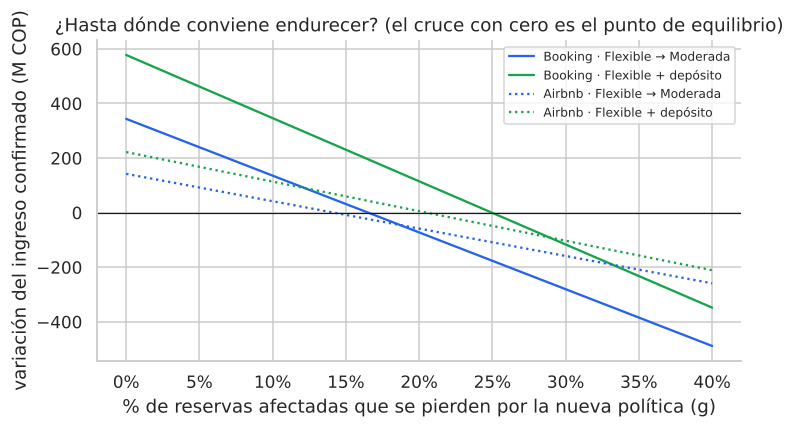

In [8]:
# Beneficio neto de Booking según cuántas de las reservas afectadas se pierden por la nueva política (g)
fig, ax = plt.subplots(figsize=(7, 4))
g = np.linspace(0, .40, 81)
for canal, ls in [("Booking", "-"), ("Airbnb", ":")]:
    for esc, col in [("Flexible → Moderada", AZUL), ("Flexible + depósito", VERDE)]:
        x = p3[(p3.canal == canal) & (p3.escenario == esc)].iloc[0]
        af = x.afectadas; tk = te[(te.canal == canal) & (te.politica_cancelacion == "Flexible") & (te.deposito_pagado == 0)].ingreso_potencial.mean()
        neto = af * tk * ((1 - g) * (1 - x.p_escenario) - (1 - x.p_flex_hoy))
        ax.plot(g, neto / 1e6, color=col, ls=ls, label=f"{canal} · {esc}")
ax.axhline(0, color="k", lw=.8); pct(ax, "x"); ax.set_xlabel("% de reservas afectadas que se pierden por la nueva política (g)")
ax.set_ylabel("variación del ingreso confirmado (M COP)"); ax.legend(fontsize=8); ax.set_title("¿Hasta dónde conviene endurecer? (el cruce con cero es el punto de equilibrio)")
plt.tight_layout(); plt.show()

## 5. Conclusiones técnicas y cifras para los demás entregables

In [9]:
c = CIF
print(f"MODELO   AUC {c['auc']:.3f} (sin 2023: {c['auc_sin2023']:.3f}) · máxima desviación de calibración {c['calib_max_desv_pp']:.1f} pp")
print(f"P1       Con el percentil 10 se aceptan ≈ {c['p1_extra_media']:.1f} reservas adicionales por noche: cobertura {c['p1_cobertura']:.1%} (meta ≥ 70 %), "
      f"incidencias {c['p1_incidencia']:.1%} de las noches (meta < 6 %), MAE {c['p1_mae']:.2f} (PDF: 3,0). Regla ingenua: {c['p1_cobertura_ing']:.1%} / {c['p1_incidencia_ing']:.1%} / {c['p1_mae_ing']:.2f}.")
print(f"P2       Exigir depósito al {c['p2_pct_marcadas']:.0%} de reservas sin pago (p > 30 %), que cancelan {c['p2_tasa_alto']:.1%}, protege ≈ {M(c['p2_protegido'])} "
      f"({c['p2_pct_recup']:.0%} del recuperable); neto {M(c['p2_neto_g5'])} si desisten 5 %, {M(c['p2_neto_g10'])} si 10 %.")
print(f"P3       Booking {c['p3_bk_dep_hoy']:.1%} → {c['p3_bk_mod_nueva']:.1%} (Moderada) / {c['p3_bk_dep_nueva']:.1%} (depósito); equilibrio {c['p3_bk_dep_be']:.1%}, tope recomendado {c['p3_bk_dep_tope']:.1%}.")
json.dump({k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in CIF.items()}, open("../../datos/cifras_tec.json", "w"), ensure_ascii=False, indent=1, default=float)

MODELO   AUC 0.770 (sin 2023: 0.768) · máxima desviación de calibración 1.4 pp
P1       Con el percentil 10 se aceptan ≈ 16.3 reservas adicionales por noche: cobertura 76.8% (meta ≥ 70 %), incidencias 7.6% de las noches (meta < 6 %), MAE 3.07 (PDF: 3,0). Regla ingenua: 75.1% / 9.1% / 3.24.
P2       Exigir depósito al 37% de reservas sin pago (p > 30 %), que cancelan 42.8%, protege ≈ $1,266 M (59% del recuperable); neto $1,086 M si desisten 5 %, $906 M si 10 %.
P3       Booking 26.9% → 23.6% (Moderada) / 21.4% (depósito); equilibrio 25.0%, tope recomendado 12.5%.
